In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [3]:
MAX_INTENSITY = 255.0
x_train_full = x_train_full.astype("float32") / MAX_INTENSITY
x_test = x_test.astype("float32") / MAX_INTENSITY

N_TRAIN = 50_000
x_val, y_val = x_train_full[N_TRAIN:], y_train_full[N_TRAIN:]
x_train, y_train = x_train_full[:N_TRAIN], y_train_full[:N_TRAIN]

In [4]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]


In [5]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (50000, 28, 28), val: (10000, 28, 28), test: (10000, 28, 28), class: 10


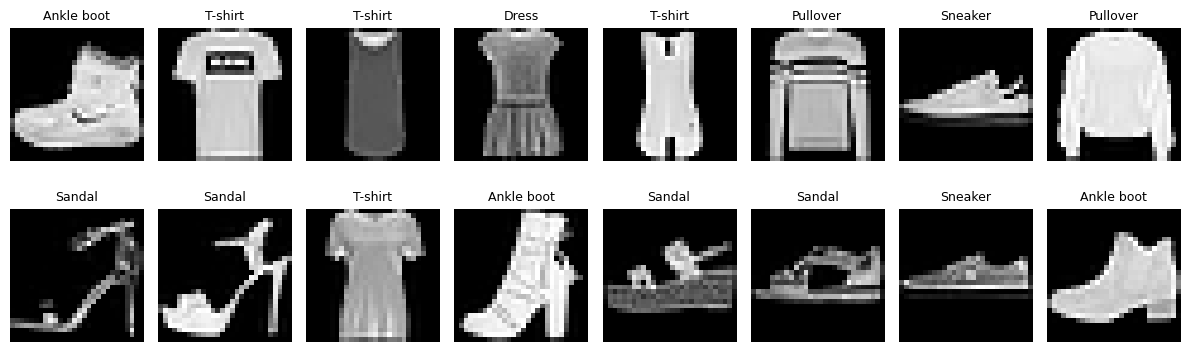

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 7, activation="relu", name="conv1", padding="same", strides=(4,4)), 
    layers.MaxPooling2D(), 
    layers.Conv2D(32, 7, activation="relu", name="conv2", padding="same", strides=(2,2)), 
    layers.MaxPooling2D(), 
    layers.Flatten(),
    layers.Dense(10, activation="softmax") 
])


cnn.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cnn.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 7, 7, 16)       │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 3, 3, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 2, 2, 32)       │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 1, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,250 (102.54 KB)

 Trainable params: 26,250 (102.54 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
hist_cnn = cnn.fit(x_train, y_train, validation_split=0.2, epochs=10, batch_size=32)

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7454 - loss: 0.7177 - val_accuracy: 0.8040 - val_loss: 0.5348
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 984us/step - accuracy: 0.8222 - loss: 0.4955 - val_accuracy: 0.8300 - val_loss: 0.4751
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8394 - loss: 0.4478 - val_accuracy: 0.8464 - val_loss: 0.4282
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 962us/step - accuracy: 0.8494 - loss: 0.4177 - val_accuracy: 0.8496 - val_loss: 0.4215
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 964us/step - accuracy: 0.8555 - loss: 0.3987 - val_accuracy: 0.8565 - val_loss: 0.3999
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 999us/step - accuracy: 0.8619 - loss: 0.3809 - val_accuracy: 0.8573 - val_loss: 0.3902
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 966us/step - accuracy: 0.8680 - loss: 0.3666 - val_accuracy: 0.8555 - val_loss: 0.4016
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 982us/step - accuracy: 0.8700 - los

## visualize filters

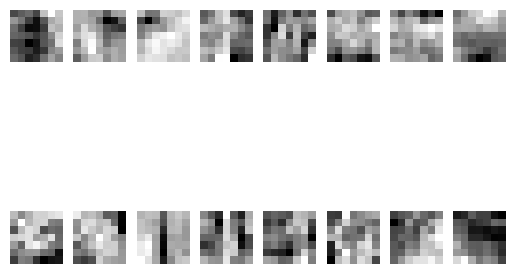

In [50]:
filters = cnn.get_layer("conv1").get_weights()[0] #shape (3, 3, 1, 16)

for i in range(16):
    plt.subplot(2, 8, i+1)
    plt.imshow(filters[:, :, 0, i], cmap="gray")
    plt.axis("off")

plt.show()

In [51]:
image = x_test[2500:2501]
image.shape

(1, 28, 28)

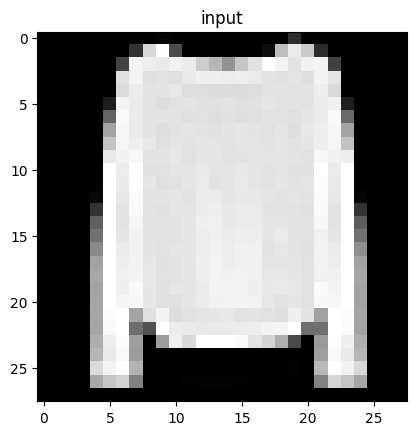

In [52]:
conv1_output = keras.Model(cnn.inputs[0], cnn.get_layer("conv1").output)(image)
conv2_output = keras.Model(cnn.inputs[0], cnn.get_layer("conv2").output)(image)


plt.imshow(image[0, :, :], cmap="gray")
plt.title("input")
plt.show()

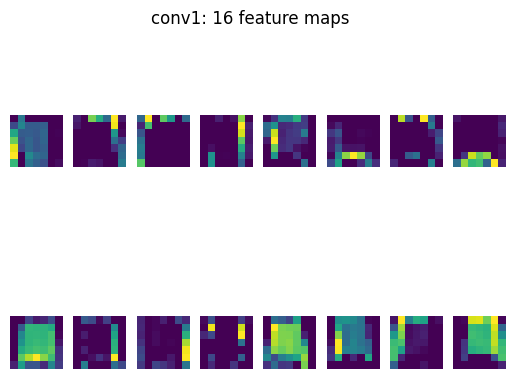

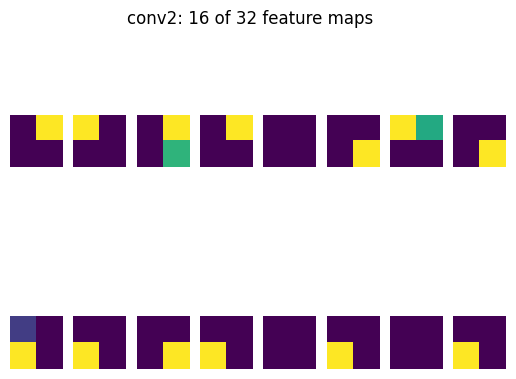

In [53]:
for title, output in [("conv1: 16 feature maps", conv1_output), ("conv2: 16 of 32 feature maps", conv2_output)]:
    for i in range(16):
        plt.subplot(2, 8, i+1)
        plt.imshow(output[0, :, :, i])
        plt.axis("off")
    plt.suptitle(title)
    plt.show()